# Comparing four landing classifiers

Four classifiers use the IBM course grid-search protocol. The snapshot has 90 records and the held-out set has 18. The course protocol standardizes before splitting, which causes leakage; these lab scores are not an unbiased production performance estimate.

Run the cells in order from the repository root or `notebooks/`. Install `requirements.txt` and run `download_inputs.py` if `data/` is missing. Local output files are written under `results/`.

## Sources and credit

Adapted from this repository's `scripts/04_predictive_models.py` and the public IBM DS0321EN Skills Network SpaceX labs. IBM and the credited lab authors, including Joseph Santarcangelo, Nayef Abou Tayoun and Yan Luo, retain their source credit. Input URLs and SHA-256 hashes are listed in `SOURCES.json`; see `ATTRIBUTION.md` for third-party terms. This notebook does not grant a new licence over third-party material.


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import pandas as pd
pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 70)

In [2]:
from pathlib import Path

import os

import matplotlib

matplotlib.use('module://matplotlib_inline.backend_inline')

from IPython.display import display

HERE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'SOURCES.json').is_file()), None)

if HERE is None:
    raise FileNotFoundError('Open this notebook from the repository root or its notebooks folder; run download_inputs.py first.')

DATA = HERE / 'data'

OUT = HERE / 'results' / '04_machine_learning'

OUT.mkdir(parents=True, exist_ok=True)

os.chdir(OUT)

_figure_number = 0

def save_current_figure():
    global _figure_number
    import matplotlib.pyplot as plt
    _figure_number += 1
    plt.savefig(OUT / f'figure_{_figure_number:02d}.png', dpi=150)
    display(plt.gcf())
    plt.close()

In [3]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn import preprocessing

from sklearn.model_selection import train_test_split

from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

def plot_confusion_matrix(y, y_predict):
    from sklearn.metrics import confusion_matrix
    plt.figure(figsize=(5.5, 4.5))
    ax = sns.heatmap(confusion_matrix(y, y_predict), annot=True, fmt='d', cbar=False, xticklabels=['IBM Class 0', 'IBM Class 1'], yticklabels=['IBM Class 0', 'IBM Class 1'])
    ax.set(xlabel='Predicted label', ylabel='True label', title='Confusion matrix: IBM target (18 test records)')
    plt.tight_layout()
    save_current_figure()

data = pd.read_csv(DATA / 'dataset_part_2.csv')

data.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,...,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,...,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,...,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,...,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,...,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,...,1.0,0,B1004,-80.577366,28.561857,0


tuned hpyerparameters :(best parameters)  {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
accuracy : 0.8464285714285713


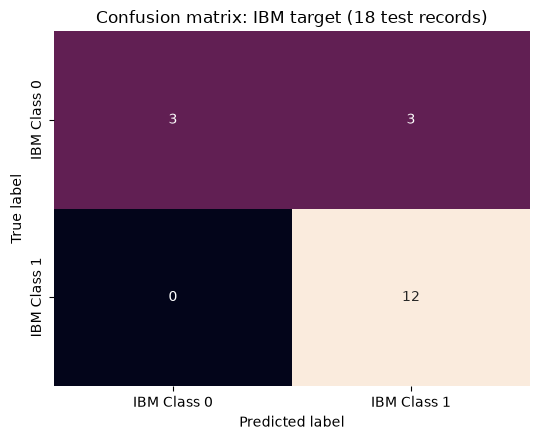

In [4]:
X = pd.read_csv(DATA / 'dataset_part_3.csv')

X.head()

Y = data['Class'].to_numpy()

assert len(Y) == len(X) == 90

transform = preprocessing.StandardScaler()

X = transform.fit_transform(X)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

Y_test.shape

parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}

parameters = {'C': [0.01, 0.1, 1], 'penalty': ['l2'], 'solver': ['lbfgs']}

lr = LogisticRegression()

logreg_cv = GridSearchCV(lr, parameters, cv=10, n_jobs=1)

logreg_cv.fit(X_train, Y_train)

print('tuned hpyerparameters :(best parameters) ', logreg_cv.best_params_)

print('accuracy :', logreg_cv.best_score_)

logreg_cv.score(X_test, Y_test)

yhat = logreg_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)

parameters = {'kernel': ('linear', 'rbf', 'poly', 'rbf', 'sigmoid'), 'C': np.logspace(-3, 3, 5), 'gamma': np.logspace(-3, 3, 5)}

svm = SVC()

tuned hpyerparameters :(best parameters)  {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
accuracy : 0.8482142857142856


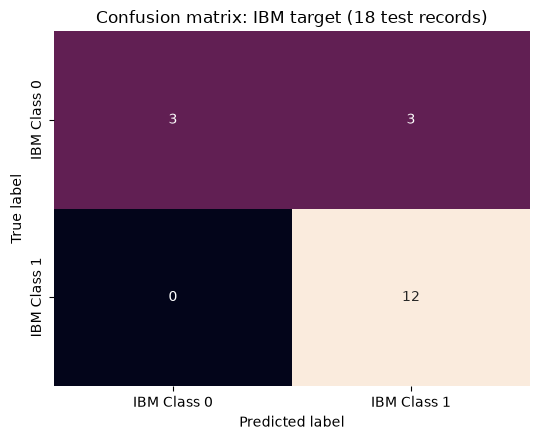

tuned hpyerparameters :(best parameters)  {'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'splitter': 'best'}
accuracy : 0.8767857142857143


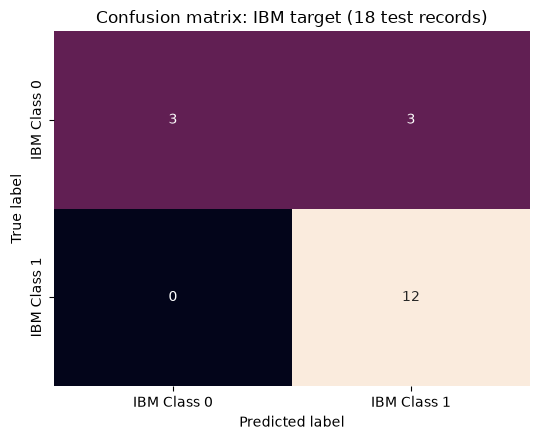

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'algorithm': ['auto', 'ball_tree', ...], 'n_neighbors': [1, 2, ...], 'p': [1, 2]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity o

In [5]:
svm_cv = GridSearchCV(svm, parameters, cv=10, n_jobs=1)

svm_cv.fit(X_train, Y_train)

print('tuned hpyerparameters :(best parameters) ', svm_cv.best_params_)

print('accuracy :', svm_cv.best_score_)

svm_cv.score(X_test, Y_test)

yhat = svm_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)

parameters = {'criterion': ['gini', 'entropy'], 'splitter': ['best', 'random'], 'max_depth': [2 * n for n in range(1, 10)], 'max_features': ['sqrt'], 'min_samples_leaf': [1, 2, 4], 'min_samples_split': [2, 5, 10]}

tree = DecisionTreeClassifier(random_state=2)

tree_cv = GridSearchCV(tree, parameters, cv=10, n_jobs=1)

tree_cv.fit(X_train, Y_train)

print('tuned hpyerparameters :(best parameters) ', tree_cv.best_params_)

print('accuracy :', tree_cv.best_score_)

tree_cv.score(X_test, Y_test)

yhat = tree_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)

parameters = {'n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], 'algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'], 'p': [1, 2]}

KNN = KNeighborsClassifier()

knn_cv = GridSearchCV(KNN, parameters, cv=10, n_jobs=1)

knn_cv.fit(X_train, Y_train)

tuned hpyerparameters :(best parameters)  {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
accuracy : 0.8482142857142858


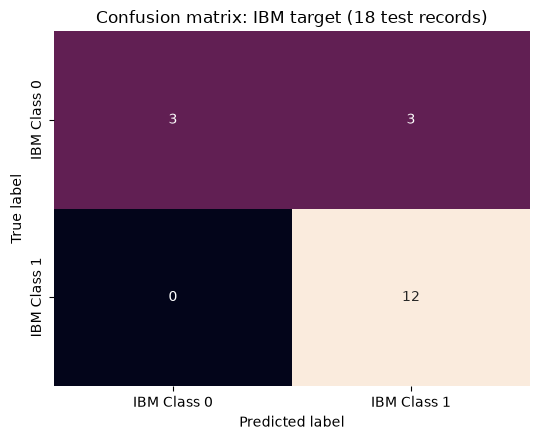

,model,cv_accuracy,test_accuracy,best_parameters
0,Logistic regression,0.846429,0.833333,"{'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}"
1,SVM,0.848214,0.833333,"{'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), '..."
2,Decision tree,0.876786,0.833333,"{'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'min..."
3,KNN,0.848214,0.833333,"{'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}"


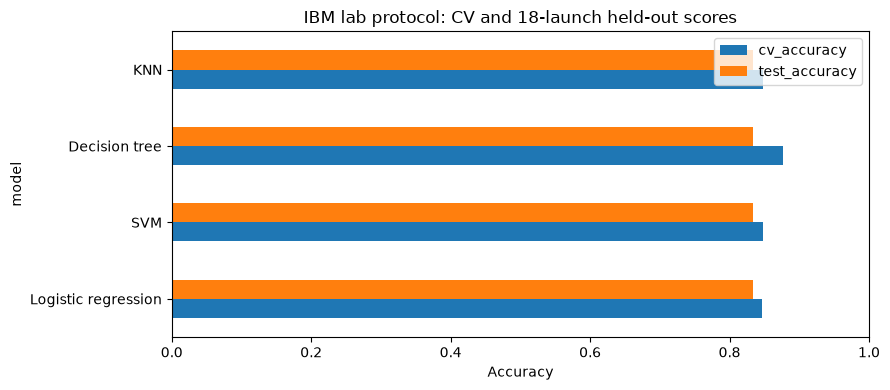

In [6]:
print('tuned hpyerparameters :(best parameters) ', knn_cv.best_params_)

print('accuracy :', knn_cv.best_score_)

knn_cv.score(X_test, Y_test)

yhat = knn_cv.predict(X_test)

plot_confusion_matrix(Y_test, yhat)

models = {'Logistic regression': logreg_cv, 'SVM': svm_cv, 'Decision tree': tree_cv, 'KNN': knn_cv}

results = pd.DataFrame([{'model': name, 'cv_accuracy': model.best_score_, 'test_accuracy': model.score(X_test, Y_test), 'best_parameters': repr(model.best_params_)} for name, model in models.items()])

display(results)

results.to_csv(OUT / 'model_results.csv', index=False)

results.set_index('model')[['cv_accuracy', 'test_accuracy']].plot.barh(figsize=(9, 4), xlim=(0, 1), xlabel='Accuracy', title='IBM lab protocol: CV and 18-launch held-out scores')

plt.tight_layout()

save_current_figure()

In [7]:
import json

from sklearn.metrics import accuracy_score, confusion_matrix

summary = []

for name, model in models.items():
    predictions = model.predict(X_test)
    assert len(predictions) == 18
    assert np.isfinite(model.cv_results_['mean_test_score']).all()
    assert abs(accuracy_score(Y_test, predictions) - model.score(X_test, Y_test)) < 1e-12
    summary.append({'model': name, 'best_cv_accuracy': float(model.best_score_), 'test_accuracy': float(model.score(X_test, Y_test)), 'correct': int((predictions == Y_test).sum()), 'test_n': len(Y_test), 'confusion_matrix': confusion_matrix(Y_test, predictions).tolist(), 'candidates': len(model.cv_results_['params'])})

(OUT / 'RESULTS.json').write_text(json.dumps({'models': summary, 'protocol_limit': 'Standardization before split follows IBM template; contains leakage. Small reused holdout, descriptive lab results only.'}, indent=2))

print(json.dumps(summary, indent=2))

[
  {
    "model": "Logistic regression",
    "best_cv_accuracy": 0.8464285714285713,
    "test_accuracy": 0.8333333333333334,
    "correct": 15,
    "test_n": 18,
    "confusion_matrix": [
      [
        3,
        3
      ],
      [
        0,
        12
      ]
    ],
    "candidates": 3
  },
  {
    "model": "SVM",
    "best_cv_accuracy": 0.8482142857142856,
    "test_accuracy": 0.8333333333333334,
    "correct": 15,
    "test_n": 18,
    "confusion_matrix": [
      [
        3,
        3
      ],
      [
        0,
        12
      ]
    ],
    "candidates": 125
  },
  {
    "model": "Decision tree",
    "best_cv_accuracy": 0.8767857142857143,
    "test_accuracy": 0.8333333333333334,
    "correct": 15,
    "test_n": 18,
    "confusion_matrix": [
      [
        3,
        3
      ],
      [
        0,
        12
      ]
    ],
    "candidates": 324
  },
  {
    "model": "KNN",
    "best_cv_accuracy": 0.8482142857142858,
    "test_accuracy": 0.8333333333333334,
    "correct": 15,
